### ПРАКТИКУМ ПО МАШИННОМУ ОБУЧЕНИЮ: КОД И АЛГОРИТМ KNN

**Темы:** Предобработка данных, Категориальное кодирование, Нормализация, Алгоритм К ближайших соседей (KNN), Подбор гиперпараметров, Метрики расстояний, Intel® Extension for Scikit-learn и Борьба с переобучением.

**Работу выполнила:** Cetvertacova Anastasia, IASD2602.

### Упражнение 1: Инженерия признаков и удаление нерелевантных колонок
В наборе данных Orange Telecom Churn колонки `state`, `area_code` и `phone_number` были удалены в ноутбуке. Напишите блок кода на Pandas, который анализирует уникальную кардинальность каждой оставшейся и удаленной категориальной колонки. Объясните с математической точки зрения, почему применение `OneHotEncoder` или `LabelBinarizer` к колонке со сотнями уникальных значений (например, `phone_number`) разрушит пространственную эффективность и вызовет высокий риск переобучения для алгоритма KNN.

In [1]:
from sklearn.preprocessing import LabelBinarizer
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics.pairwise import euclidean_distances

import time
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.feature_selection import SelectKBest
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error
from sklearn.metrics import recall_score

from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_moons

from __future__ import print_function
import os
data_path = ['data']

import pandas as pd
import numpy as np

filepath = os.sep.join(data_path + ['Orange_Telecom_Churn_Data.csv'])
data = pd.read_csv(filepath)

Видно, что у ```phone_number``` уникальных значений столько же, сколько клиентов всего, следовательно у каждого клиента свой номер. У остальных столбцов значений мало.

```OneHotEncoder``` превращает столбец с `n` значениями в `n` новых столбцов: в строке стоит 1 в столбце своего значения и 0 в остальных. 

`LabelBinarizer` на столбце с более чем двумя значениями делает то же самое.

Для phone_number получается n = 5000. Вместо одного столбца появляется 5000, то есть матрица 5000 × 5000 = 25 миллионов чисел, около 200 МБ. Почти все числа нули, и информации в ней нет. Все расстояния `одинаковы`. Два разных клиента отличаются ровно в двух позициях: у одного 1 в своём столбце, у другого 1 в своём. Расстояние между любыми двумя разными клиентами равно 

`√(1² + 1²) = √2 ≈ 1.41`. 

Значит, по этому блоку никто не ближе к другому, и поиск соседей теряет смысл. Остальные 17 признаков с расстояниями порядка 0.1–0.5 тонут на фоне этих 5000. 

Так же, у каждого клиента своя уникальная единица, поэтому он однозначно отличается от всех остальных. Модель может просто запомнить, что клиент с этим номером остался. Для нового клиента такого столбца нет, и запомненное не помогает. Это и есть переобучение, на обучающих данных ответ идеальный, а на новых нет.

In [2]:
cat_cols = ['state', 'area_code', 'phone_number', 'intl_plan', 'voice_mail_plan', 'churned']
print(data[cat_cols].nunique())
print('Всего клиентов:', len(data))

state                51
area_code             3
phone_number       5000
intl_plan             2
voice_mail_plan       2
churned               2
dtype: int64
Всего клиентов: 5000


In [3]:
data.drop(['state', 'area_code', 'phone_number'], axis=1, inplace=True)

In [4]:
data.columns

Index(['account_length', 'intl_plan', 'voice_mail_plan',
       'number_vmail_messages', 'total_day_minutes', 'total_day_calls',
       'total_day_charge', 'total_eve_minutes', 'total_eve_calls',
       'total_eve_charge', 'total_night_minutes', 'total_night_calls',
       'total_night_charge', 'total_intl_minutes', 'total_intl_calls',
       'total_intl_charge', 'number_customer_service_calls', 'churned'],
      dtype='str')

### Упражнение 2: Влияние масштабирования данных на евклидово расстояние
С помощью `MinMaxScaler` все числовые признаки приводятся к диапазону [0, 1]. Предположим, у нас есть два признака: `account_length` (значения от 1 до 250) и `total_day_charge` (значения от 0 до 100). Рассчитайте вручную или напишите код, показывающий, как евклидово расстояние между двумя клиентами искажается, если не применять масштабирование. Что произойдет, если использовать `StandardScaler` вместо `MinMaxScaler`, когда в распределении данных присутствуют выбросы (outliers)?

In [5]:
lb = LabelBinarizer()

for col in ['intl_plan', 'voice_mail_plan', 'churned']:
    data[col] = lb.fit_transform(data[col])

Без масштабирования расстояние между клиентами 0 и 1 равно ```109.11```, после масштабирования ```0.51```. 

Сами числа сравнивать нельзя, потому что у них разные шкалы. Важно, что без масштабирования расстояние почти полностью определяют признаки с **крупными значениями**: минуты звонков и ```account_length```. Признаки с **маленькими значениями** (```intl_plan, voice_mail_plan```, звонки в поддержку) почти не влияют на расстояние, хотя для оттока они **важны**. 

Из-за этого KNN выбирает ближайших соседей по нескольким столбцам и игнорирует остальные. После ```MinMaxScaler``` все признаки лежат в диапазоне [0, 1] и влияют на расстояние примерно одинаково.

In [6]:
data_raw = data.copy()

msc = MinMaxScaler()
data = pd.DataFrame(msc.fit_transform(data), 
                    columns=data.columns)

cols = [c for c in data.columns if c != 'churned']

In [ ]:
# без масштабирования
print(euclidean_distances(data_raw.iloc[[0, 1]]).round(2)[0, 1])

# после масштабирования
print(euclidean_distances(data.iloc[[0, 1]]).round(2)[0, 1])

109.11
0.51


```MinMaxScaler``` растягивает столбец между минимумом и максимумом, а ```StandardScaler``` считает среднее и стандартное отклонение:

новое значение = (значение - среднее) / разброс

```Выброс``` — это клиент с очень большим значением, например счёт 500 при обычных 20–60. Он портит оба масштабировщика, но по-разному:

- ```MinMaxScaler``` опирается на максимум. Максимум становится 500, и все обычные клиенты сжимаются в узкую полосу рядом с 0. Это сильное искажение.
- ```StandardScaler``` опирается на среднее и разброс. Выброс увеличивает их, поэтому обычные клиенты тоже сжимаются, а выброс остаётся далеко. Но на большом наборе данных один выброс сдвигает среднее и разброс слабее, чем максимум, поэтому ```StandardScaler``` обычно искажает меньше. Если выбросов много, разброс раздувается сильно.

### Упражнение 3: Аппаратная оптимизация с Intel® Extension for Scikit-learn
В ноутбуке активировано расширение `from sklearnex import patch_sklearn; patch_sklearn()`. Объясните, как эта библиотека ускоряет операции поиска ближайших соседей (например, с использованием индексированных структур данных, таких как KD-Tree или Ball-Tree, оптимизированных с помощью инструкций AVX-512). Напишите фрагмент кода, измеряющий время выполнения (`timeit`) для обучения `KNeighborsClassifier` с патчем Intel и без него на синтетическом наборе из 100 000 объектов.

In [8]:
from sklearnex import patch_sklearn, unpatch_sklearn

# Создание синтетических данных
X = np.random.rand(100000, 10)
y = np.random.randint(0, 2, 100000)

def measure():
    from sklearn.neighbors import KNeighborsClassifier
    knn = KNeighborsClassifier(n_neighbors=5)

    start = time.time()
    knn.fit(X, y)
    knn.predict(X)
    return time.time() - start

# Без патча
unpatch_sklearn()
t_plain = measure()

# С патчем
patch_sklearn()
t_intel = measure()

print('Без патча:', round(t_plain, 2), 'сек')
print('С патчем: ', round(t_intel, 2), 'сек')
print('Ускорение в', round(t_plain / t_intel, 1), 'раз')

ModuleNotFoundError: No module named 'sklearnex'

Основная работа `KNN` это поиск ближайших соседей, для каждого нового объекта нужно посчитать расстояния до множества объектов обучающей выборки. Расширение `Intel` подменяет реализацию `sklearn` на оптимизированную из библиотеки `oneDAL`. 

Ускорение идёт за счёт трёх вещей:
- Все ядра процессора работают. Расстояния считаются параллельно, а не одним потоком.
- Процессор обрабатывает сразу несколько чисел за одну команду. `AVX-512` одна из таких инструкций, она работает только на процессорах, которые её поддерживают.
- При небольшом числе признаков (у нас 10) поиск ускоряется деревьями (KD-Tree), которые отбрасывают заведомо далёкие объекты вместо перебора всех. 

### Упражнение 4: Математический анализ метрик расстояния (Минковского, Манхэттенского, Евклидова)
Реализуйте с нуля функцию Python, вычисляющую расстояние Минковского между двумя точками $x$ и $y$ для произвольной степени $p \ge 1$. Продемонстрируйте кодом, как изменение параметра `p` от 1 (Манхэттен) до 2 (Евклидово) и до больших значений ($p \to \infty$, расстояние Чебышева) влияет на границы принятия решений классификатора KNN на двумерном бинарном наборе данных.

Проверила реализацию функции `minkowski_distance` на точках (0, 0) и (3, 4). 

- При `p=1` расстояние равно 7.0, это сумма модулей разниц (3 + 4), то есть расстояние Манхэттена. 
- При `p=2` расстояние равно 5.0, это корень из суммы квадратов (√(9 + 16)), то есть евклидово расстояние. 
- При `p=50` результат равен 4.0, а расстояние Чебышева, то есть наибольшая разница по одному признаку, тоже равно 4. Значит, с ростом `p` формула Минковского приближается к расстоянию Чебышева, и `p=50` служит приближением к бесконечности, которую нельзя подставить в формулу напрямую. 

При малом `p` в расстояние вносят вклад все признаки. При большом `p` расстояние определяется почти только тем признаком, по которому клиенты отличаются сильнее всего, а остальные признаки на него почти не влияют. 

In [ ]:
def minkowski_distance(x, y, p):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    return np.sum(np.abs(x - y) ** p) ** (1 / p)

a = np.array([0, 0])
b = np.array([3, 4])

print('p=1:  ', minkowski_distance(a, b, 1))             
print('p=2:  ', minkowski_distance(a, b, 2))             
print('p=50: ', round(minkowski_distance(a, b, 50), 2))  
print('Чебышев:', np.max(np.abs(a - b)))    

p=1:   7.0
p=2:   5.0
p=50:  4.0
Чебышев: 4


Обучила KNN с `n_neighbors=5` на двумерном бинарном наборе данных `make_moons` с тремя вариантами расстояния (Манхэттена, евклидово и Чебышева) и сравнила их предсказания на 1000 случайных точках. 

Расстояния `p=1` и `p=2` дали разные классы на 30 точках из 1000 (3%), а `p=2` и Чебышев на 28 точках из 1000 (2.8%). 

Точка получает другой класс только тогда, когда она лежит рядом с границей между классами и смена расстояния сдвигает эту границу. 

Поэтому параметр `p` влияет на границы принятия решений, но на этих данных влияние небольшое. На 97% точек все три модели согласны. 

In [ ]:
X, labels = make_moons(n_samples=200, noise=0.3, random_state=0)
new_points = np.random.RandomState(1).uniform([-2, -1.5], [3, 2], size=(1000, 2))

pred_p1 = KNeighborsClassifier(n_neighbors=5, p=1).fit(X, labels).predict(new_points)
pred_p2 = KNeighborsClassifier(n_neighbors=5, p=2).fit(X, labels).predict(new_points)
pred_inf = KNeighborsClassifier(n_neighbors=5, metric='chebyshev').fit(X, labels).predict(new_points)

print('p=1 и p=2 различаются на', (pred_p1 != pred_p2).sum(), 'из 1000 точек')
print('p=2 и Чебышев различаются на', (pred_p2 != pred_inf).sum(), 'из 1000 точек')

p=1 и p=2 различаются на 30 из 1000 точек
p=2 и Чебышев различаются на 28 из 1000 точек


### Упражнение 5: Парадокс 100% точности при K=3 на обучающей выборке
Как отмечалось в вопросе 5 ноутбука, запуск KNN с параметром `weights='distance'` или $K=1$ на полном наборе данных (без разделения train/test) дает точность 1.0 (100%). Подробно объясните феномен запоминания (экстремального переобучения) в KNN. Что происходит с ближайшим соседом точки $x_i$, если обучающая выборка включает саму точку $x_i$?

`KNN` не обучается в обычном смысле, а запоминает всю обучающую выборку. Когда мы предсказываем ответ для точки xᵢ, модель ищет её ближайших соседей среди запомненных точек. Но xᵢ тоже входит в выборку, поэтому ближайшим соседом оказывается она сама, на расстоянии 0.

- При `K=1` единственный сосед - сама точка, и модель возвращает её же настоящую метку. Точность 1.0.
- При `K=3` с равными весами голосуют трое: сама точка и ещё два соседа. Если оба других имеют противоположный класс, они перевешивают, и модель ошибается. 

In [ ]:
x_cols = [x for x in data.columns if x != 'churned']

X_data = data[x_cols]
y_data = data['churned']

Точность 1.0 не означает, что модель хорошая. Это экстремальное переобучение: модель запомнила данные и подсматривает ответ в собственной памяти, а не нашла закономерность. 

На новых клиентах, которых в выборке нет, такого соседа с расстоянием 0 не будет, и точность окажется заметно ниже. Чтобы получить честную оценку, нужно разделить данные на обучающую и тестовую части и считать точность на тестовой выборке.

In [ ]:
knn = KNeighborsClassifier(n_neighbors=1).fit(X_data, y_data)

def accuracy(real, predict):
    return sum(real == predict) / float(real.shape[0])

print(accuracy(y_data, knn.predict(X_data))) 

1.0


### Упражнение 6: Реализация собственного алгоритма KNN с нуля
Не используя классы из `sklearn`, напишите собственный класс Python `CustomKNN`, реализующий интерфейсы `fit(X, y)` и `predict(X_test, k)`. Класс должен использовать евклидово расстояние, поддерживать простое мажоритарное голосование и эффективно обрабатывать матрицы NumPy. Протестируйте класс на небольшом подмножестве данных о оттоке (churn).

In [ ]:
class Custom:
    def __init__(self):
        pass
        
    def fit(self, X, y):
        self.X_train = np.array(X, dtype=float)
        self.y_train = np.array(y, dtype=int)
        
    def predict(self, X_test, k=3):
        X_test = np.array(X_test, dtype=float)

        # строки это тестовые клиенты, столбцы обучающие
        dist = np.sqrt(((X_test[:, None, :] - self.X_train[None, :, :]) ** 2).sum(axis=2))

        # номера k ближайших соседей для каждого тестового клиента
        idx = np.argsort(dist, axis=1)[:, :k]

        # метки соседей и голосование
        labels = self.y_train[idx]
        return np.array([np.bincount(row).argmax() for row in labels])

In [ ]:
y = y_data.astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X_data, y, test_size=0.3, stratify=y, random_state=42)

model = Custom()
model.fit(X_train, y_train)
y_pred = model.predict(X_test, k=3)

print('Точность:', (y_pred == y_test.astype(int).values).mean())

Точность: 0.904


### Упражнение 7: Перекрестная проверка (Cross-Validation) для выбора оптимального K
Чтобы избежать ловушки оценки на обучающей выборке, реализуйте процедуру 5-Fold Cross-Validation с использованием `StratifiedKFold` из Scikit-learn. Напишите скрипт, вычисляющий среднюю точность и стандартное отклонение для значений K от 1 до 30. Постройте график ошибки валидации в зависимости от K и определите оптимальное значение.

До этого модель проверялась на тех же клиентах, на которых она училась, и получала завышенную точность (1.0 при k=1).

Кросс-валидация решает это так:

- Все клиенты делятся на 5 равных частей.
- Модель учится на 4 частях, а проверяется на пятой, которую не видела.
- Это повторяется 5 раз, и каждая часть один раз побывает экзаменом.
- Берётся средняя точность по пяти проверкам. Она честная, потому что модель всегда проверялась на незнакомых клиентах.

Выполнила 5-кратную стратифицированную кросс-валидацию для k от 1 до 30: данные делились на 5 частей, модель по очереди обучалась на четырёх и проверялась на пятой, а результаты усреднялись. Это даёт честную оценку, потому что модель всегда проверяется на клиентах, которых не видела. 

Оптимальное k: 5


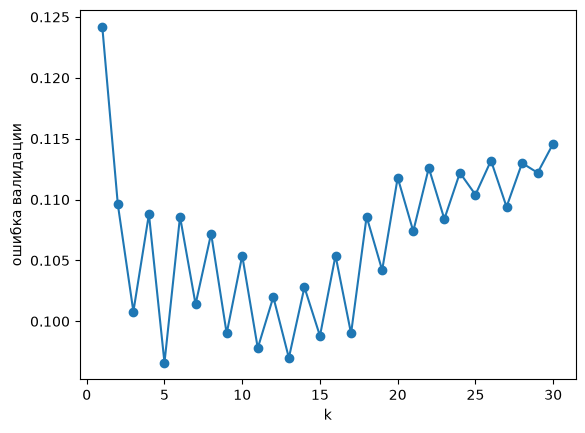

In [ ]:
y = y_data.astype(int)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

ks = range(1, 31)
means = []   
stds = []  

for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_data, y, cv=skf)
    means.append(scores.mean())
    stds.append(scores.std())

errors = 1 - np.array(means)

best_k = list(ks)[errors.argmin()]
print('Оптимальное k:', best_k)

plt.plot(ks, errors, marker='o')
plt.xlabel('k')
plt.ylabel('ошибка валидации')
plt.show()

- k=1. Ошибка самая высокая, около 0.124. Модель смотрит на одного соседа и реагирует на случайные выбросы. Для сравнения: в вопросе 6 на обучающих данных при k=1 точность была 1.0. Здесь на незнакомых клиентах она на 12 процентных пунктов ниже, и это прямо показывает, что прежняя оценка была завышена.
- От k=1 до k=5. Ошибка быстро падает.

Минимум. Он при k=5, ошибка около 0.0966 (точность около 90.3%). Почти так же хорош k=13 (около 0.097).
После k≈17. Ошибка медленно растёт до 0.115 при k=30: модель слишком сильно усредняет и перестаёт замечать различия между клиентами.

### Упражнение 8: Работа с несбалансированными классами (Class Imbalance)
В наборе данных Orange Telecom мажоритарный класс представляют клиенты, которые не ушли (`churned = False`), а ушедшие — меньшинство. Объясните, почему метрика `accuracy` (точность) в данном контексте вводит в заблуждение. Измените код оценки для расчета матрицы ошибок (Confusion Matrix), Precision, Recall и F1-score с использованием `sklearn.metrics`.

`accuracy` вводит в заблуждение, потому что ушедших клиентов в данных около 14%, остальные 86% остались. Значит, модель, которая всегда отвечает клиент останется, уже получит точность около 0.86 и при этом не найдёт ни одного ушедшего. А именно их мы и хотим находить.

In [ ]:
print(y_data.value_counts(normalize=True))

churned
0.0    0.8586
1.0    0.1414
Name: proportion, dtype: float64


- `Матрица ошибок это таблица 2×2`: сколько клиентов каждого класса модель угадала и сколько перепутала.
- `Precision` (точность предсказаний «ушёл»): из тех, кого модель назвала уходящими, сколько действительно ушли. Низкий precision значит много ложных тревог.
- `Recall` (полнота): из всех реально ушедших, скольких модель нашла. Низкий recall значит, что мы пропускаем уходящих клиентов.
- `F1-score` это одно число, которое объединяет precision и recall. Оно высокое, только если высоки оба.

In [ ]:
y = y_data.astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X_data, y, test_size=0.3, stratify=y, random_state=42)

knn = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
y_pred = knn.predict(X_test)

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[1264   24]
 [ 126   86]]
              precision    recall  f1-score   support

           0       0.91      0.98      0.94      1288
           1       0.78      0.41      0.53       212

    accuracy                           0.90      1500
   macro avg       0.85      0.69      0.74      1500
weighted avg       0.89      0.90      0.89      1500



Матрица ошибок показывает, что из 212 ушедших клиентов модель правильно определила 86 и пропустила 126, а из 1288 оставшихся она ошиблась только на 24. Для класса ушёл precision равен 0.78, recall 0.41, F1 0.53. 

Значит, если модель называет клиента уходящим, она обычно права, но находит меньше половины тех, кто действительно уходит. Общая accuracy 0.90 выглядит высокой, но модель, всегда отвечающая клиент останется, получила бы около 0.86, поэтому accuracy скрывает слабый recall. 

Для задачи удержания клиентов важнее найти как можно больше уходящих, поэтому оценивать модель нужно по recall и F1 по классу ушёл, а не по accuracy.

### Упражнение 9: Влияние весов расстояния (`weights='distance'`) против равномерных весов
Сравните поведение модели KNN при `weights='uniform'` и `weights='distance'`. Напишите эксперимент на Python, оценивающий чувствительность модели к шуму (выбросам в пространстве признаков) для обоих типов весов. Какой вариант более уязвим к шуму и почему?

В KNN соседи могут голосовать по-разному:

- weights='uniform': у каждого из k соседей один голос.
- weights='distance': голос соседа тем весомее, чем он ближе

Данные делятся на обучающую и тестовую части. В обучающей части мы нарочно портим ответы: у доли клиентов (0%, 10%, 20%) меняем ушёл на остался и наоборот. Это и есть шум. Для каждого уровня шума обучаем две модели (uniform и distance) и проверяем обе на чистой тестовой выборке. Смотрим, у какого варианта точность падает быстрее с ростом шума.

In [ ]:
y = y_data.astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X_data, y, test_size=0.3, stratify=y, random_state=42)

rng = np.random.RandomState(0)

for noise in [0, 0.1, 0.2]:
    y_noisy = y_train.values.copy()
    flip = rng.rand(len(y_noisy)) < noise
    y_noisy[flip] = 1 - y_noisy[flip]

    for w in ['uniform', 'distance']:
        knn = KNeighborsClassifier(n_neighbors=5, weights=w).fit(X_train, y_noisy)
        print('шум', noise, w, round(knn.score(X_test, y_test), 4))

шум 0 uniform 0.9
шум 0 distance 0.8993
шум 0.1 uniform 0.8833
шум 0.1 distance 0.8813
шум 0.2 uniform 0.8373
шум 0.2 distance 0.8373


Сравнила KNN с `weights='uniform'` и `weights='distance'` при нарастающем шуме в метках обучающей выборки (0%, 10%, 20% перевёрнутых ответов) с `k=5`, проверяя на чистой тестовой выборке. 

Без шума точность составила 0.9000 и 0.8993, при шуме 10% — 0.8833 и 0.8813, при шуме 20% — 0.8373 у обоих вариантов. 

Шум заметно снижает качество обеих моделей, но разница между вариантами не превышает 0.002 (около 3 клиентов из 1500) и находится в пределах случайных колебаний. 

Значит, на этих данных ни один из вариантов нельзя назвать заметно более уязвимым к шуму. 

Теоретически `distance` должен быть более чувствителен к шуму в метках, потому что близкий сосед с неверной меткой получает большой вес и может перевесить остальных. Влияние весов проявилось бы сильнее при малом числе признаков или при очень близких дубликатах точек.

### Упражнение 10: Проклятие размерности (Curse of Dimensionality)
Алгоритм KNN основан на измерении расстояний в многомерных пространствах. С ростом числа признаков объем пространства растет экспоненциально, и точки становятся равноудаленными. Напишите небольшой кейс или эксперимент на Python, показывающий, как искусственное увеличение размерности (добавление колонок случайного шума к данным churn) ухудшает производительность классификатора KNN.

KNN определяет похожесть клиентов по расстоянию между ними. Расстояние считается по всем признакам сразу. Если добавить много признаков, которые ничего не значат (случайный шум), они начинают вносить в расстояние такой же вклад, как и важные. Настоящие различия между клиентами тонут в случайных, и ближайшие соседи становятся случайными. Модель начинает ошибаться.

Это и есть проклятие размерности. В формулировке задания оно звучит так: с ростом числа признаков точки становятся почти равноудалёнными, и понятие ближайший сосед теряет смысл.

Берём 17 настоящих признаков в диапазоне [0, 1] и дописываем к ним столбцы случайных чисел от 0 до 1: сначала 0, потом 10, 50, 100, 200. 

Для каждого варианта обучаем KNN и смотрим на три вещи:

- Accuracy 
- Recall по классу ушёл
- Разброс расстояний: отношение стандартного отклонения расстояний между клиентами к их среднему. Эта цифра прямо показывает, что точки становятся равноудалёнными

In [ ]:
y = y_data.astype(int)
rng = np.random.RandomState(0)

for n_noise in [0, 10, 50, 100, 200]:
    # n_noise столбцов случайного шума справа от настоящих признаков
    noise = rng.rand(len(X_data), n_noise)
    X_new = np.hstack([X_data.values, noise])

    # отдельная тестовая часть
    X_train, X_test, y_train, y_test = train_test_split(
        X_new, y, test_size=0.3, stratify=y, random_state=42)
    pred = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train).predict(X_test)

    # расстояния между 500 клиентами и их относительный разброс
    d = euclidean_distances(X_new[:500])
    d = d[np.triu_indices(500, k=1)]
    spread = d.std() / d.mean()

    print('шума:', n_noise,
          '| accuracy:', round((pred == y_test).mean(), 3),
          '| recall:', round(recall_score(y_test, pred), 3),
          '| разброс расстояний:', round(spread, 3))

шума: 0 | accuracy: 0.9 | recall: 0.406 | разброс расстояний: 0.366
шума: 10 | accuracy: 0.86 | recall: 0.104 | разброс расстояний: 0.181
шума: 50 | accuracy: 0.855 | recall: 0.061 | разброс расстояний: 0.085
шума: 100 | accuracy: 0.85 | recall: 0.028 | разброс расстояний: 0.059
шума: 200 | accuracy: 0.848 | recall: 0.024 | разброс расстояний: 0.042


Чем больше шума, тем хуже модель находит уходящих клиентов, и расстояния между клиентами выравниваются.

### Упражнение 11: KNN для регрессии против классификации
KNN также применим для регрессии (`KNeighborsRegressor`). Напишите скрипт, применяющий `KNeighborsRegressor` для предсказания непрерывной переменной (например, `total_day_charges` на основе минут и звонков). 

Раньше KNN отвечал категорией (ушёл или остался) и выбирал ответ голосованием соседей. 

В регрессии нужно предсказать число, например счёт за дневные звонки. Для этого `KNeighborsRegressor` находит `k` ближайших клиентов и берёт среднее их значений. 

MSE (средний квадрат ошибки) показывает, насколько предсказания в среднем отличаются от настоящих значений: чем меньше, тем лучше. Ошибки возводятся в квадрат, поэтому большие промахи наказываются сильнее.

In [10]:
# минуты и звонки (в масштабе [0, 1]).
X = data[['total_day_minutes', 'total_day_calls']]
y = data_raw['total_day_charge']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)

for k in [1, 3, 5, 10, 20, 30]:
    knn = KNeighborsRegressor(n_neighbors=k).fit(X_train, y_train)
    mse = mean_squared_error(y_test, knn.predict(X_test))
    print('k =', k, '| MSE =', round(mse, 4))

k = 1 | MSE = 0.1555
k = 3 | MSE = 0.1751
k = 5 | MSE = 0.2551
k = 10 | MSE = 0.3833
k = 20 | MSE = 0.6129
k = 30 | MSE = 0.7402


MSE это размер ошибки, чем он меньше, тем точнее модель, он растёт вместе с `k`: 

0.1076 при k=1 и 0.2877 при k=30. Значит, чем больше соседей мы усредняем, тем сильнее ошибается модель, потому что счёт за звонки почти полностью зависит от минут разговора, больше минут, больше счёт. Поэтому клиент с почти таким же числом минут имеет почти такой же счёт.

При k=1 модель берёт ближайшего клиента, то есть того, у кого минуты почти те же. Его счёт почти совпадает с нужным.

При k=30 модель усредняет счёт тридцати клиентов. Среди них попадаются те, у кого минут заметно больше или меньше, и их счёт тянет среднее в сторону. Предсказание получается менее точным.

### Упражнение 12: Пайплайны машинного обучения с `Pipeline` и `GridSearchCV`
Постройте полный пайплайн в Scikit-learn, включающий: (1) `MinMaxScaler`, (2) опционально селектор признаков (`SelectKBest`) и (3) `KNeighborsClassifier`. Используйте `GridSearchCV` для одновременного поиска оптимальных гиперпараметров: количества соседей K in {3, 5, 7, 9, 11}, типа весов (`uniform`, `distance`) и метрики расстояния (p=1 или p=2). Выведите лучший набор гиперпараметров и оценку на тестовой выборке.

Изначально все упражнения проделывались по отдельным шагам - масштабирование, модель, подбор k в цикле. Здесь всё собирается в одну цепочку, а подбор настроек делает `GridSearchCV`.

- `Pipeline` связывает шаги в один объект - масштабирование, отбор признаков, модель.
- `SelectKBest` оставляет только k самых полезных признаков и отбрасывает остальные. Это защита от проклятия размерности (упражнение 10).
- `GridSearchCV` перебирает все комбинации настроек, для каждой делает кросс-валидацию (упражнении 7) и выбирает лучшую.

In [9]:
# до масштабирования
X = data_raw.drop(columns='churned')
y = data_raw['churned'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42)

# шаги
pipe = Pipeline([
    ('scale', MinMaxScaler()),
    ('select', SelectKBest()),
    ('knn', KNeighborsClassifier())
])

# настройки перебираем
params = {
    'select__k': [10, 'all'],               # 10 лучших признаков или все
    'knn__n_neighbors': [3, 5, 7, 9, 11],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2]
}

grid = GridSearchCV(pipe, params, cv=5)
grid.fit(X_train, y_train)

print('Лучшие настройки:', grid.best_params_)
print('Точность на кросс-валидации:', round(grid.best_score_, 4))
print('Точность на тестовой выборке:', round(grid.score(X_test, y_test), 4))

Лучшие настройки: {'knn__n_neighbors': 7, 'knn__p': 1, 'knn__weights': 'uniform', 'select__k': 10}
Точность на кросс-валидации: 0.9189
Точность на тестовой выборке: 0.9167


Был построен пайплайн из `MinMaxScaler`, `SelectKBest` и `KNeighborsClassifier` и с помощью `GridSearchCV` (5-кратная кросс-валидация на обучающей выборке) перебрала k ∈ {3, 5, 7, 9, 11}, тип весов, параметр расстояния p ∈ {1, 2} и число отбираемых признаков (10 или все 17). 

Лучшая комбинация оказалась 7 соседей, расстояние Манхэттена (p=1), равные веса (`uniform`), 10 лучших признаков. 

Точность на кросс-валидации составила 0.9189, на тестовой выборке 0.9167. Близость этих значений говорит о том, что модель не переобучена и оценка честная. 

Выбор 10 признаков вместо всех 17 согласуется с проклятием размерности, то есть неинформативные признаки ухудшают поиск ближайших соседей, а их удаление улучшает качество. 

Использование пайплайна гарантирует, что масштабирование обучается только на обучающих частях в каждой итерации кросс-валидации, поэтому информация о проверочных данных не попадает в модель. 